In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Advertising.csv")

df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [3]:
df.shape

(200, 4)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [5]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


In [6]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate rows:
0


In [7]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


In [8]:
print("Average Sales:", df["Sales"].mean())
print("Minimum Sales:", df["Sales"].min())
print("Maximum Sales:", df["Sales"].max())
print("Median Sales:", df["Sales"].median())

Average Sales: 15.130500000000001
Minimum Sales: 1.6
Maximum Sales: 27.0
Median Sales: 16.0


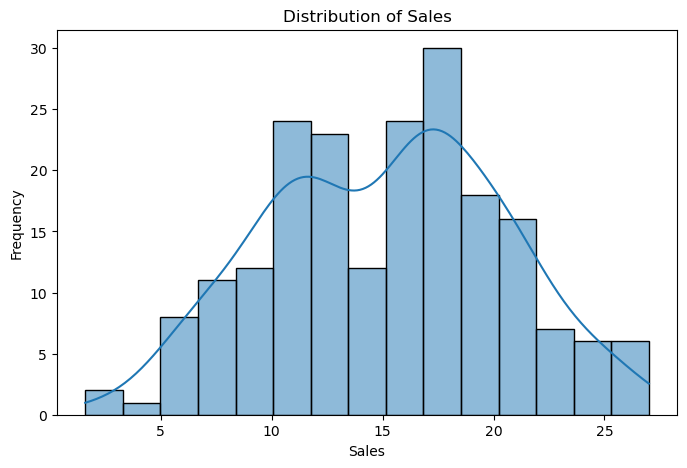

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Sales", bins=15, kde=True)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

In [10]:
df[["TV", "Radio", "Newspaper"]].mean()

TV           147.0425
Radio         23.2640
Newspaper     30.5540
dtype: float64

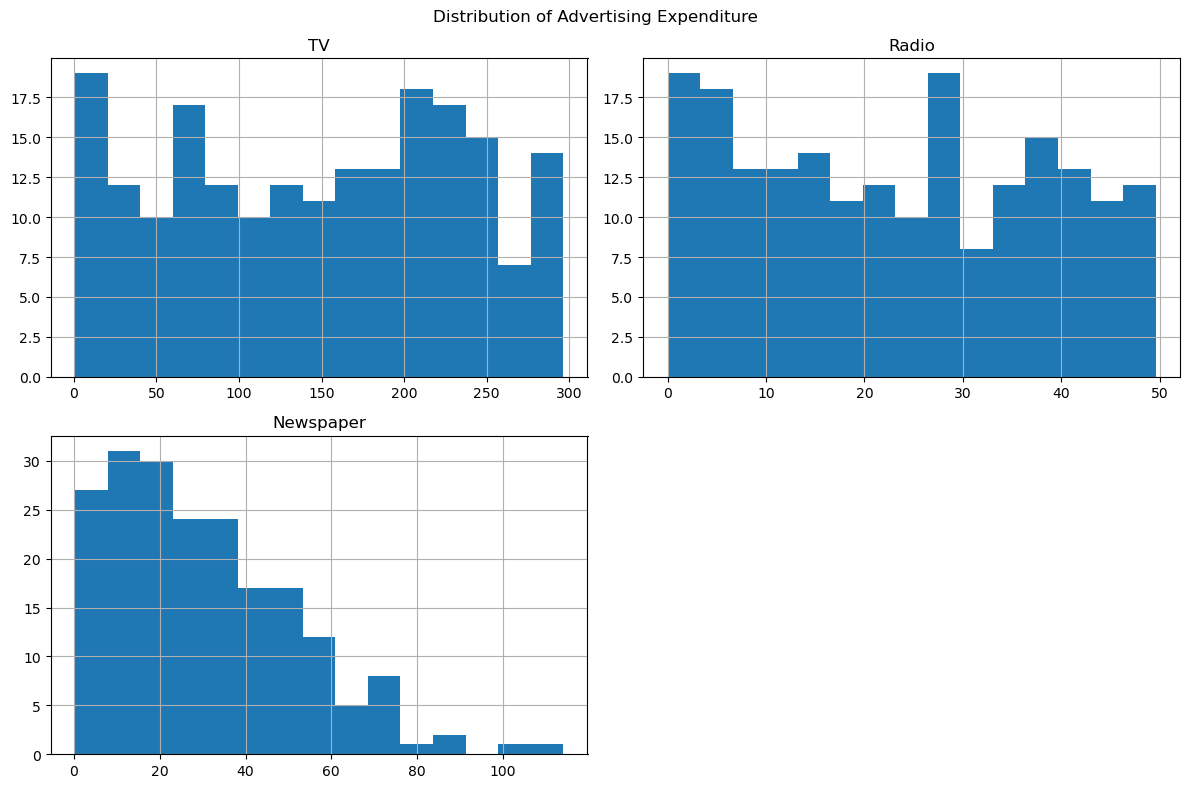

In [11]:
df[["TV", "Radio", "Newspaper"]].hist(
    figsize=(12, 8),
    bins=15
)

plt.suptitle("Distribution of Advertising Expenditure")
plt.tight_layout()
plt.show()

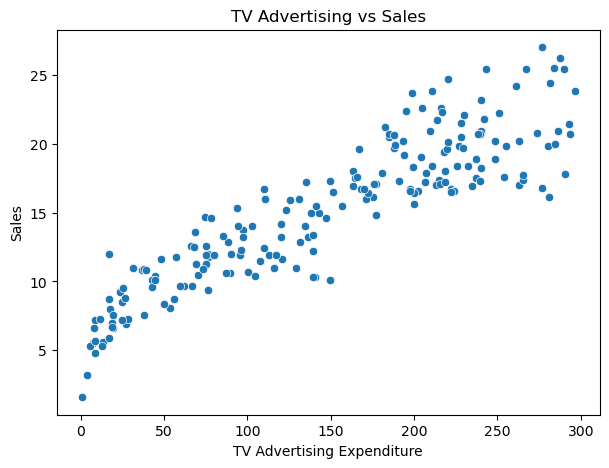

In [12]:
plt.figure(figsize=(7, 5))

sns.scatterplot(data=df, x="TV", y="Sales")

plt.title("TV Advertising vs Sales")
plt.xlabel("TV Advertising Expenditure")
plt.ylabel("Sales")
plt.show()

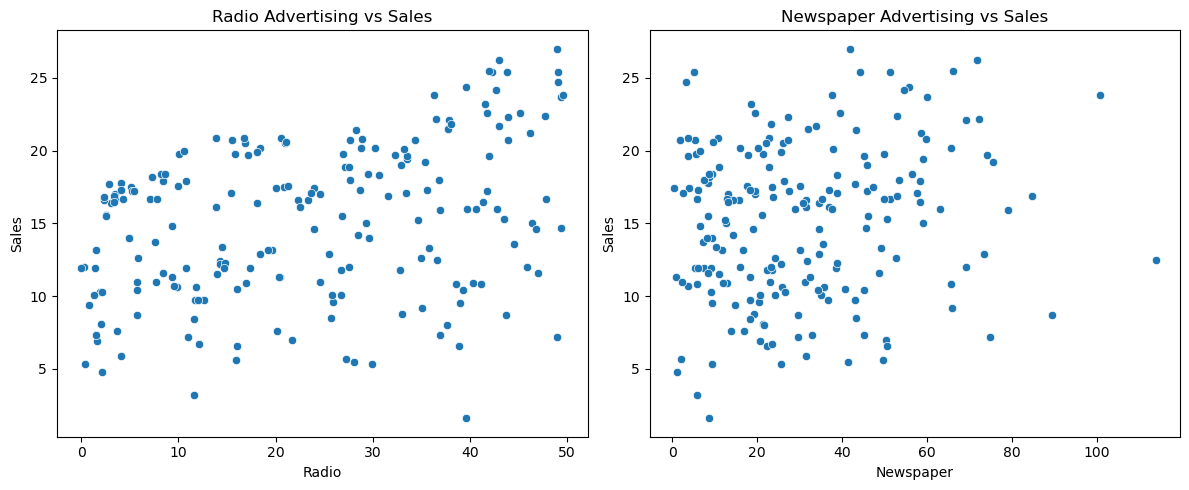

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(data=df, x="Radio", y="Sales", ax=axes[0])
axes[0].set_title("Radio Advertising vs Sales")

sns.scatterplot(data=df, x="Newspaper", y="Sales", ax=axes[1])
axes[1].set_title("Newspaper Advertising vs Sales")

plt.tight_layout()
plt.show()

In [14]:
correlation = df.corr()

print(correlation)

                 TV     Radio  Newspaper     Sales
TV         1.000000  0.054809   0.056648  0.901208
Radio      0.054809  1.000000   0.354104  0.349631
Newspaper  0.056648  0.354104   1.000000  0.157960
Sales      0.901208  0.349631   0.157960  1.000000


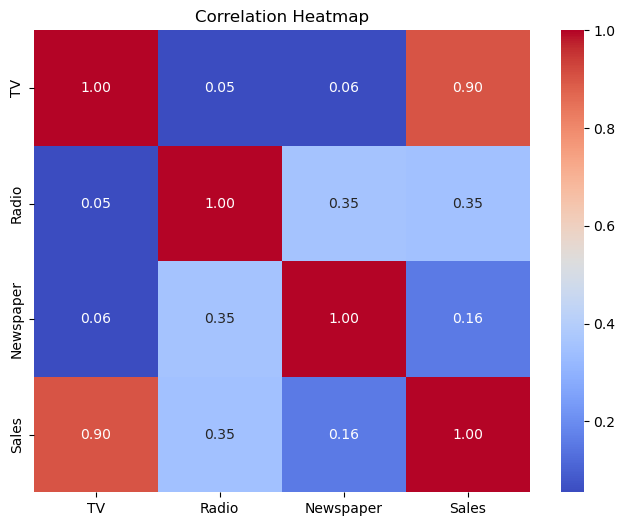

In [15]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [16]:
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
      TV  Radio  Newspaper
0  230.1   37.8       69.2
1   44.5   39.3       45.1
2   17.2   45.9       69.3
3  151.5   41.3       58.5
4  180.8   10.8       58.4

Target:
0    22.1
1    10.4
2    12.0
3    16.5
4    17.9
Name: Sales, dtype: float64


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (160, 3)
Testing data: (40, 3)


In [18]:
from sklearn.linear_model import LinearRegression

In [19]:
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

LinearRegression()

In [20]:
print("Intercept:", lr_model.intercept_)

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lr_model.coef_
})

print(coefficients)

Intercept: 4.714126402214134
     Feature  Coefficient
0         TV     0.054509
1      Radio     0.100945
2  Newspaper     0.004337


In [21]:
y_pred = lr_model.predict(X_test)

print("Actual Sales:")
print(y_test.head(10).values)

print("\nPredicted Sales:")
print(y_pred[:10])

Actual Sales:
[16.9 22.4 21.4  7.3 24.7 12.6 22.3  8.4 16.5 16.1]

Predicted Sales:
[17.0347724  20.40974033 23.72398873  9.27278518 21.68271879 12.56940161
 21.08119452  8.69035045 17.23701254 16.66657475]


In [22]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 1.274826210954934
MSE: 2.907756910271091
RMSE: 1.7052146229349228
R2 Score: 0.9059011844150826


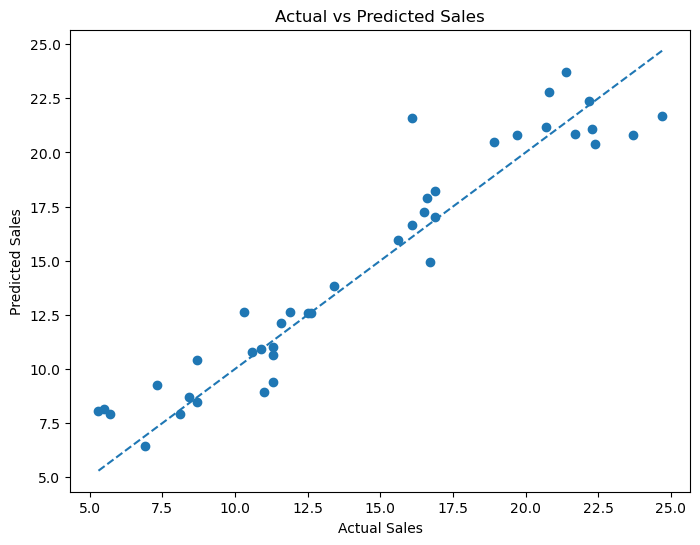

In [23]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.show()

In [24]:
from sklearn.ensemble import RandomForestRegressor

In [25]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [26]:
rf_pred = rf_model.predict(X_test)

print("Actual Sales:")
print(y_test.head(10).values)

print("\nPredicted Sales:")
print(rf_pred[:10])

Actual Sales:
[16.9 22.4 21.4  7.3 24.7 12.6 22.3  8.4 16.5 16.1]

Predicted Sales:
[17.299 22.482 19.77   6.784 22.961 13.471 22.595  9.579 16.887 16.793]


In [27]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print("----------------------")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Results
----------------------
MAE: 0.9179999999999993
MSE: 1.4374328500000009
RMSE: 1.1989298770153327
R2 Score: 0.9534827934927883


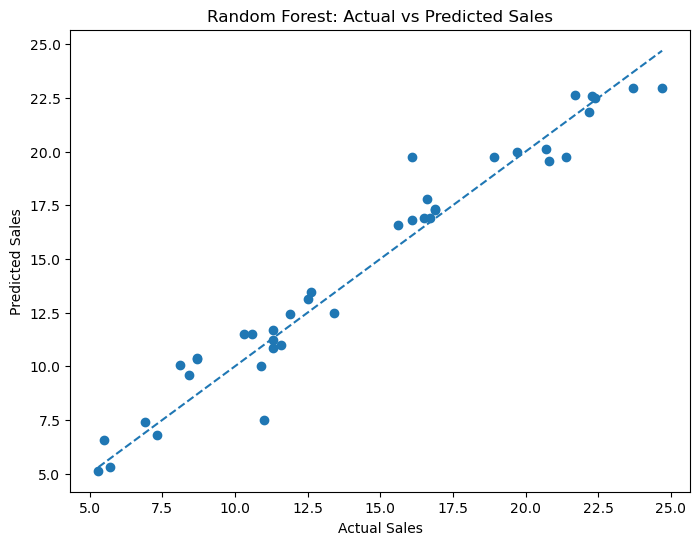

In [28]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Random Forest: Actual vs Predicted Sales")
plt.show()

In [29]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2 Score": [r2, rf_r2]
})

print(comparison)

               Model       MAE      RMSE  R2 Score
0  Linear Regression  1.274826  1.705215  0.905901
1      Random Forest  0.918000  1.198930  0.953483


In [30]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

     Feature  Importance
0         TV    0.845355
1      Radio    0.136642
2  Newspaper    0.018003


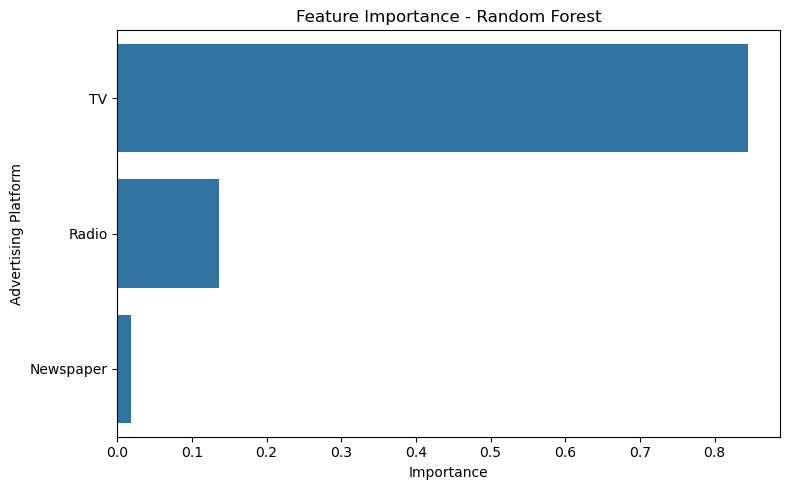

In [31]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Advertising Platform")
plt.tight_layout()
plt.show()

In [32]:
from sklearn.model_selection import cross_val_score

lr_scores = cross_val_score(
    lr_model,
    X,
    y,
    cv=5,
    scoring="r2"
)

print("Linear Regression scores:", lr_scores)
print("Mean R2:", lr_scores.mean())
print("Standard deviation:", lr_scores.std())

Linear Regression scores: [0.87556263 0.93177791 0.92150403 0.84554586 0.90247132]
Mean R2: 0.8953723525274103
Standard deviation: 0.03141250965862174


In [33]:
rf_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=5,
    scoring="r2"
)

print("Random Forest scores:", rf_scores)
print("Mean R2:", rf_scores.mean())
print("Standard deviation:", rf_scores.std())

Random Forest scores: [0.93416583 0.97275478 0.94442102 0.90784741 0.94911315]
Mean R2: 0.9416604403430396
Standard deviation: 0.021116400039870833


In [34]:
cv_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "Mean R2": [lr_scores.mean(), rf_scores.mean()],
    "Std Dev": [lr_scores.std(), rf_scores.std()]
})

print(cv_comparison)

               Model   Mean R2   Std Dev
0  Linear Regression  0.895372  0.031413
1      Random Forest  0.941660  0.021116


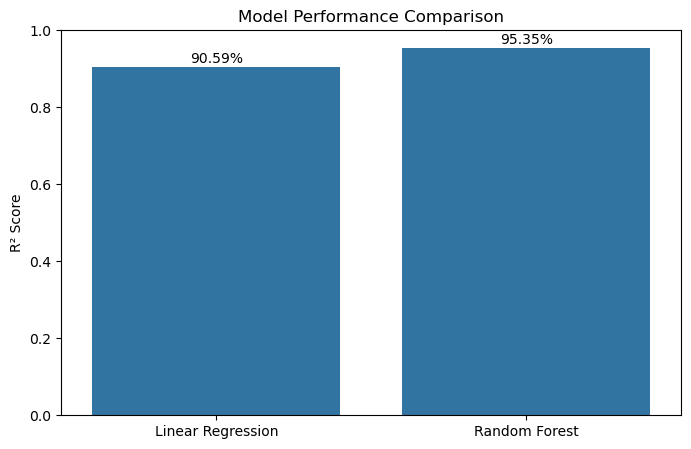

In [35]:
model_names = ["Linear Regression", "Random Forest"]
r2_scores = [r2, rf_r2]

plt.figure(figsize=(8, 5))

sns.barplot(
    x=model_names,
    y=r2_scores
)

plt.title("Model Performance Comparison")
plt.ylabel("R² Score")
plt.ylim(0, 1)

for i, score in enumerate(r2_scores):
    plt.text(i, score + 0.01, f"{score:.2%}", ha="center")

plt.show()